In [1]:

import pandas as pd

# Load the HCV dataset

df = pd.read_csv("/home/jovyan/work/bd-a1/data/dataset.csv")

print("First 5 rows:")
display(df.head())


First 5 rows:


,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [2]:

# 1. Display dataset shape
print("Dataset Shape:")
print(df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display data types
print("\nData Types:")
print(df.dtypes)

# 4. Display dataset information
print("\nDataset Information:")
df.info()

# 5. Display descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include='all'))


Dataset Shape:
(615, 14)

Column Names:
['Unnamed: 0', 'Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']

Data Types:
Unnamed: 0      int64
Category          str
Age             int64
Sex               str
ALB           float64
ALP           float64
ALT           float64
AST           float64
BIL           float64
CHE           float64
CHOL          float64
CREA          float64
GGT           float64
PROT          float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    str    
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    str    
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-n

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
count,615.000000,615,615.000000,615,614.000000,597.000000,614.000000,615.000000,615.000000,615.000000,605.000000,615.000000,615.000000,614.000000
unique,NaN,5,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,0=Blood Donor,NaN,m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,533,NaN,377,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,308.000000,NaN,47.408130,NaN,41.620195,68.283920,28.450814,34.786341,11.396748,8.196634,5.368099,81.287805,39.533171,72.044137
std,177.679487,NaN,10.055105,NaN,5.780629,26.028315,25.469689,33.090690,19.673150,2.205657,1.132728,49.756166,54.661071,5.402636
min,1.000000,NaN,19.000000,NaN,14.900000,11.300000,0.900000,10.600000,0.800000,1.420000,1.430000,8.000000,4.500000,44.800000
25%,154.500000,NaN,39.000000,NaN,38.800000,52.500000,16.400000,21.600000,5.300000,6.935000,4.610000,67.000000,15.700000,69.300000
50%,308.000000,NaN,47.000000,NaN,41.950000,66.200000,23.000000,25.900000,7.300000,8.260000,5.300000,77.000000,23.300000,72.200000
75%,461.500000,NaN,54.000000,NaN,45.200000,80.100000,33.075000,32.900000,11.200000,9.590000,6.060000,88.000000,40.200000,75.400000


In [3]:

# Check missing values in each column
print("Missing Values per Column:")
print(df.isnull().sum())

# Total number of missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values per Column:
Unnamed: 0     0
Category       0
Age            0
Sex            0
ALB            1
ALP           18
ALT            1
AST            0
BIL            0
CHE            0
CHOL          10
CREA           0
GGT            0
PROT           1
dtype: int64

Total Missing Values:
31


In [4]:

# Check duplicate rows
print("Duplicate Rows:")
print(df.duplicated().sum())

# Check duplicates without the row identifier
print("\nDuplicates excluding Unnamed: 0:")
print(df.drop(columns=["Unnamed: 0"]).duplicated().sum())

# Display dataset shape before cleaning
print("\nDataset Shape Before Cleaning:")
print(df.shape)


Duplicate Rows:
0

Duplicates excluding Unnamed: 0:
0

Dataset Shape Before Cleaning:
(615, 14)


In [5]:

# Create a copy of the original dataset
df_clean = df.copy()

# Display shape before cleaning
print("Shape Before Cleaning:")
print(df_clean.shape)

# Remove the unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Fill missing numerical values using the median
numerical_columns = df_clean.select_dtypes(
    include=["number"]
).columns

for col in numerical_columns:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

# Check missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

# Display shape after cleaning
print("\nShape After Cleaning:")
print(df_clean.shape)

# Display first 5 rows
print("\nFirst 5 Rows After Cleaning:")
display(df_clean.head(5))


Shape Before Cleaning:
(615, 14)

Missing Values After Cleaning:
Category    0
Age         0
Sex         0
ALB         0
ALP         0
ALT         0
AST         0
BIL         0
CHE         0
CHOL        0
CREA        0
GGT         0
PROT        0
dtype: int64

Shape After Cleaning:
(615, 13)

First 5 Rows After Cleaning:


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [6]:

from pathlib import Path

# Define output folder
output_folder = Path("/home/jovyan/work/bd-a1/output")

# Save cleaned dataset
df_clean.to_csv(output_folder / "cleaned_data.csv", index=False)

# Verify the file
print("Cleaned dataset saved successfully!")
print("File exists:", (output_folder / "cleaned_data.csv").exists())
print("Final dataset shape:", df_clean.shape)


Cleaned dataset saved successfully!
File exists: True
Final dataset shape: (615, 13)


In [7]:

# Select patients older than 50 using loc
patients_over_50 = df_clean.loc[
    df_clean["Age"] > 50,
    ["Age", "Sex", "Category", "ALT", "AST"]
]

print("Patients Older Than 50:")
display(patients_over_50.head(10))

print("Number of Patients Older Than 50:")
print(patients_over_50.shape[0])


Patients Older Than 50:


,Age,Sex,Category,ALT,AST
206,51,m,0=Blood Donor,23.8,28.6
207,51,m,0=Blood Donor,25.5,27.7
208,51,m,0=Blood Donor,27.4,23.9
209,51,m,0=Blood Donor,17.6,28.3
210,51,m,0=Blood Donor,14.7,19.2
211,51,m,0=Blood Donor,31.8,28.1
212,51,m,0=Blood Donor,33.2,32.9
213,51,m,0=Blood Donor,20.1,26.8
214,52,m,0=Blood Donor,47.4,23.8
215,52,m,0=Blood Donor,47.9,23.7


Number of Patients Older Than 50:
231


In [8]:

# Select first 5 rows and first 4 columns
print("First 5 Rows and First 4 Columns:")

display(df_clean.iloc[0:5, 0:4])


First 5 Rows and First 4 Columns:


,Category,Age,Sex,ALB
0,0=Blood Donor,32,m,38.5
1,0=Blood Donor,32,m,38.5
2,0=Blood Donor,32,m,46.9
3,0=Blood Donor,32,m,43.2
4,0=Blood Donor,32,m,39.2


In [9]:

import numpy as np

# Select non-consecutive row ranges using np.r_
selected_rows = np.r_[0:3, 10:13]

print("Selected Rows Using np.r_:")
print(selected_rows)

# Use iloc with np.r_
display(df_clean.iloc[selected_rows, 0:5])


Selected Rows Using np.r_:
[ 0  1  2 10 11 12]


,Category,Age,Sex,ALB,ALP
0,0=Blood Donor,32,m,38.5,52.5
1,0=Blood Donor,32,m,38.5,70.3
2,0=Blood Donor,32,m,46.9,74.7
10,0=Blood Donor,32,m,44.3,52.3
11,0=Blood Donor,33,m,46.4,68.2
12,0=Blood Donor,33,m,36.3,78.6


In [10]:

# Create a copy of the cleaned dataset
df_transformed = df_clean.copy()

# Encode Sex column
df_transformed["Sex_Encoded"] = df_transformed["Sex"].map({
    "m": 1,
    "f": 0
})

print("Sex Encoding:")
display(df_transformed[["Sex", "Sex_Encoded"]].head(10))


Sex Encoding:


,Sex,Sex_Encoded
0,m,1
1,m,1
2,m,1
3,m,1
4,m,1
5,m,1
6,m,1
7,m,1
8,m,1
9,m,1


In [11]:

# Create age groups using pd.cut
df_transformed["Age_Group"] = pd.cut(
    df_transformed["Age"],
    bins=[0, 30, 45, 60, float("inf")],
    labels=["Young", "Adult", "Middle Aged", "Senior"]
)

print("Age Groups:")
display(df_transformed[["Age", "Age_Group"]].head(10))

print("\nNumber of Patients in Each Age Group:")
print(df_transformed["Age_Group"].value_counts())


Age Groups:


,Age,Age_Group
0,32,Adult
1,32,Adult
2,32,Adult
3,32,Adult
4,32,Adult
5,32,Adult
6,32,Adult
7,32,Adult
8,32,Adult
9,32,Adult



Number of Patients in Each Age Group:
Age_Group
Middle Aged    290
Adult          255
Senior          63
Young            7
Name: count, dtype: int64


In [12]:

import numpy as np

# Create AST/ALT ratio
df_transformed["AST_ALT_Ratio"] = np.where(
    df_transformed["ALT"] > 0,
    df_transformed["AST"] / df_transformed["ALT"],
    np.nan
)

print("New Feature: AST/ALT Ratio")
display(
    df_transformed[
        ["AST", "ALT", "AST_ALT_Ratio"]
    ].head(10)
)


New Feature: AST/ALT Ratio


,AST,ALT,AST_ALT_Ratio
0,22.1,7.7,2.870130
1,24.7,18.0,1.372222
2,52.6,36.2,1.453039
3,22.6,30.6,0.738562
4,24.8,32.6,0.760736
5,19.7,18.5,1.064865
6,17.8,17.5,1.017143
7,31.1,35.8,0.868715
8,21.2,23.2,0.913793
9,20.0,20.3,0.985222


In [13]:

print("Dataset Shape After Transformations:")
print(df_transformed.shape)

print("\nNew Columns:")
print(df_transformed[
    ["Sex_Encoded", "Age_Group", "AST_ALT_Ratio"]
].head())

print("\nMissing Values in New Features:")
print(df_transformed[
    ["Sex_Encoded", "Age_Group", "AST_ALT_Ratio"]
].isnull().sum())


Dataset Shape After Transformations:
(615, 16)

New Columns:
   Sex_Encoded Age_Group  AST_ALT_Ratio
0            1     Adult       2.870130
1            1     Adult       1.372222
2            1     Adult       1.453039
3            1     Adult       0.738562
4            1     Adult       0.760736

Missing Values in New Features:
Sex_Encoded      0
Age_Group        0
AST_ALT_Ratio    0
dtype: int64


In [14]:
# Simple Random Sampling (20%)
random_sample = df_transformed.sample(
    frac=0.2,
    random_state=42
)

print("Simple Random Sampling:")
print("Sample Shape:", random_sample.shape)

display(random_sample.head(10))


Simple Random Sampling:
Sample Shape: (123, 16)


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,Sex_Encoded,Age_Group,AST_ALT_Ratio
248,0=Blood Donor,55,m,28.1,65.5,16.6,17.5,2.8,5.58,4.39,65.0,26.2,62.4,1,Middle Aged,1.054217
365,0=Blood Donor,39,f,31.4,106.0,16.6,17.0,2.4,5.95,5.30,68.0,22.9,72.3,0,Adult,1.024096
432,0=Blood Donor,48,f,43.7,50.1,17.3,26.3,8.1,8.15,5.38,64.0,13.4,73.1,0,Middle Aged,1.520231
610,3=Cirrhosis,62,f,32.0,416.6,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5,0,Senior,18.694915
132,0=Blood Donor,44,m,35.5,81.7,27.5,29.5,6.4,8.81,6.65,83.0,24.1,68.0,1,Adult,1.072727
602,3=Cirrhosis,61,m,39.0,102.9,27.3,143.2,15.0,5.38,4.88,72.3,400.3,73.4,1,Senior,5.245421
188,0=Blood Donor,49,m,41.2,96.0,25.0,27.7,15.6,7.12,5.61,92.0,37.8,68.7,1,Middle Aged,1.108000
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,1,Adult,1.453039
271,0=Blood Donor,59,m,38.4,61.2,15.9,27.2,3.0,6.88,6.89,91.0,14.0,64.5,1,Middle Aged,1.710692
77,0=Blood Donor,38,m,48.4,44.9,23.4,22.1,7.9,10.53,7.51,87.0,43.2,82.6,1,Adult,0.944444


In [15]:

from sklearn.model_selection import train_test_split

# Stratified Sampling (20%)
stratified_sample, _ = train_test_split(
    df_transformed,
    train_size=0.2,
    stratify=df_transformed["Category"],
    random_state=42
)

print("Stratified Sampling:")
print("Sample Shape:", stratified_sample.shape)

display(stratified_sample.head(10))


Stratified Sampling:
Sample Shape: (123, 16)


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,Sex_Encoded,Age_Group,AST_ALT_Ratio
559,1=Hepatitis,58,m,43.0,99.1,12.2,63.2,13.0,5.95,6.15,147.3,491.0,65.6,1,Middle Aged,5.180328
204,0=Blood Donor,50,m,39.7,96.5,54.8,30.8,3.3,8.98,5.66,82.0,52.4,65.8,1,Middle Aged,0.562044
416,0=Blood Donor,46,f,37.9,59.5,33.0,25.0,3.7,6.06,5.30,92.0,43.9,70.0,0,Middle Aged,0.757576
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,1,Adult,1.453039
180,0=Blood Donor,48,m,43.4,41.2,18.4,21.2,9.8,7.19,6.37,80.0,15.8,68.9,1,Middle Aged,1.152174
338,0=Blood Donor,34,f,36.2,70.9,14.3,21.6,3.7,9.82,5.59,65.0,27.4,74.3,0,Adult,1.510490
528,0=Blood Donor,64,f,39.8,68.1,20.5,24.8,5.8,7.53,7.58,56.0,14.2,65.8,0,Senior,1.209756
571,2=Fibrosis,53,m,46.0,66.2,34.0,43.0,14.0,8.77,4.00,112.0,203.0,76.0,1,Middle Aged,1.264706
177,0=Blood Donor,48,m,43.1,83.9,20.8,27.4,18.3,9.82,6.14,90.0,16.4,74.9,1,Middle Aged,1.317308
553,1=Hepatitis,41,m,42.0,39.6,26.5,77.6,42.0,9.67,9.67,57.7,143.4,75.8,1,Adult,2.928302


In [16]:

import numpy as np

# Get all age groups
clusters = df_transformed["Age_Group"].dropna().unique()

# Randomly select one complete age group
rng = np.random.default_rng(42)
selected_cluster = rng.choice(clusters)

# Select all patients in that group
cluster_sample = df_transformed[
    df_transformed["Age_Group"] == selected_cluster
]

print("Cluster Sampling:")
print("Selected Cluster:", selected_cluster)
print("Sample Shape:", cluster_sample.shape)

display(cluster_sample.head(10))


Cluster Sampling:
Selected Cluster: Adult
Sample Shape: (255, 16)


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,Sex_Encoded,Age_Group,AST_ALT_Ratio
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,1,Adult,2.870130
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,1,Adult,1.372222
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,1,Adult,1.453039
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,1,Adult,0.738562
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,1,Adult,0.760736
5,0=Blood Donor,32,m,41.6,43.3,18.5,19.7,12.3,9.92,6.05,111.0,91.0,74.0,1,Adult,1.064865
6,0=Blood Donor,32,m,46.3,41.3,17.5,17.8,8.5,7.01,4.79,70.0,16.9,74.5,1,Adult,1.017143
7,0=Blood Donor,32,m,42.2,41.9,35.8,31.1,16.1,5.82,4.60,109.0,21.5,67.1,1,Adult,0.868715
8,0=Blood Donor,32,m,50.9,65.5,23.2,21.2,6.9,8.69,4.10,83.0,13.7,71.3,1,Adult,0.913793
9,0=Blood Donor,32,m,42.4,86.3,20.3,20.0,35.2,5.46,4.45,81.0,15.9,69.9,1,Adult,0.985222


In [17]:

# Calculate category percentages
original_dist = df_transformed["Category"].value_counts(
    normalize=True
) * 100

random_dist = random_sample["Category"].value_counts(
    normalize=True
) * 100

stratified_dist = stratified_sample["Category"].value_counts(
    normalize=True
) * 100

cluster_dist = cluster_sample["Category"].value_counts(
    normalize=True
) * 100

# Combine distributions into one table
comparison = pd.concat(
    [
        original_dist,
        random_dist,
        stratified_dist,
        cluster_dist
    ],
    axis=1
)

comparison.columns = [
    "Original (%)",
    "Random (%)",
    "Stratified (%)",
    "Cluster (%)"
]

print("Sampling Distribution Comparison:")
display(comparison.fillna(0).round(2))


Sampling Distribution Comparison:


,Original (%),Random (%),Stratified (%),Cluster (%)
Category,,,,
0=Blood Donor,86.67,78.05,86.99,92.16
3=Cirrhosis,4.88,7.32,4.88,2.35
1=Hepatitis,3.90,7.32,4.07,4.31
2=Fibrosis,3.41,4.88,3.25,1.18
0s=suspect Blood Donor,1.14,2.44,0.81,0.00


In [18]:

import pandas as pd
import numpy as np

# Select numerical columns
numerical_data = df_clean.select_dtypes(
    include=["number"]
)

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))


Correlation Matrix:


,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
Age,1.00,-0.20,0.17,-0.01,0.09,0.03,-0.08,0.12,-0.02,0.15,-0.15
ALB,-0.20,1.00,-0.14,0.00,-0.19,-0.22,0.38,0.20,-0.00,-0.16,0.55
ALP,0.17,-0.14,1.00,0.17,0.06,0.05,0.03,0.12,0.15,0.44,-0.06
ALT,-0.01,0.00,0.17,1.00,0.27,-0.04,0.15,0.07,-0.04,0.25,0.10
AST,0.09,-0.19,0.06,0.27,1.00,0.31,-0.21,-0.21,-0.02,0.49,0.04
BIL,0.03,-0.22,0.05,-0.04,0.31,1.00,-0.33,-0.16,0.03,0.22,-0.04
CHE,-0.08,0.38,0.03,0.15,-0.21,-0.33,1.00,0.42,-0.01,-0.11,0.29
CHOL,0.12,0.20,0.12,0.07,-0.21,-0.16,0.42,1.00,-0.05,-0.01,0.21
CREA,-0.02,-0.00,0.15,-0.04,-0.02,0.03,-0.01,-0.05,1.00,0.12,-0.03
GGT,0.15,-0.16,0.44,0.25,0.49,0.22,-0.11,-0.01,0.12,1.00,-0.01


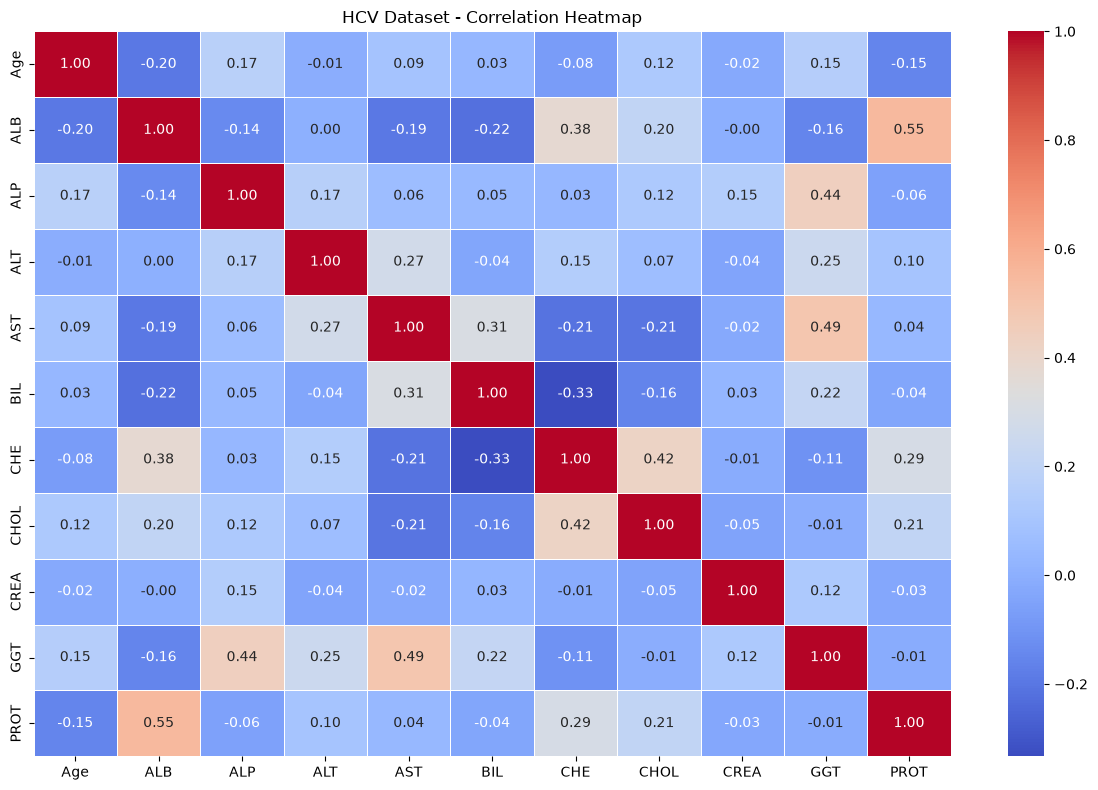

Correlation heatmap saved successfully!


In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("HCV Dataset - Correlation Heatmap")
plt.tight_layout()

# Save the figure
figures_folder = Path(
    "/home/jovyan/work/bd-a1/output/figures"
)

figures_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_folder / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully!")


In [20]:

# Select the upper triangle of the correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

# Remove NaN values
correlation_pairs = upper_triangle.stack().dropna()

# Sort by absolute correlation strength
sorted_pairs = correlation_pairs.abs().sort_values(
    ascending=False
)

# Get strongest correlations
strongest = correlation_pairs.loc[
    sorted_pairs.head(5).index
]

# Get weakest correlations
weakest = correlation_pairs.loc[
    sorted_pairs.tail(5).index
]

print("Top 5 Strongest Correlations:")
display(strongest)

print("\nTop 5 Weakest Correlations:")
display(weakest)


Top 5 Strongest Correlations:


ALB  PROT    0.549975
AST  GGT     0.491263
ALP  GGT     0.440012
CHE  CHOL    0.420215
ALB  CHE     0.375817
dtype: float64


Top 5 Weakest Correlations:


CHE   CREA   -0.011157
CHOL  GGT    -0.007185
Age   ALT    -0.005690
ALB   CREA   -0.001594
      ALT     0.001444
dtype: float64

In [21]:

### Correlation Analysis Interpretation

# The correlation analysis shows that ALB and PROT have
# the strongest positive correlation (r = 0.550),
# suggesting a moderate positive linear relationship.

# AST and GGT also show a moderate positive correlation
# (r = 0.491).

# The weakest relationship is between ALB and ALT
# (r = 0.0014), indicating almost no linear correlation.

# Correlation does not imply causation because two
# variables may be associated due to other factors
# without one directly causing changes in the other.


In [22]:

# Count patients in each category
print("Number of Patients in Each Category:")
print(df_clean["Category"].value_counts())

# Calculate category percentages
print("\nCategory Percentages:")
print(
    df_clean["Category"].value_counts(
        normalize=True
    ) * 100
)


Number of Patients in Each Category:
Category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: count, dtype: int64

Category Percentages:
Category
0=Blood Donor             86.666667
3=Cirrhosis                4.878049
1=Hepatitis                3.902439
2=Fibrosis                 3.414634
0s=suspect Blood Donor     1.138211
Name: proportion, dtype: float64


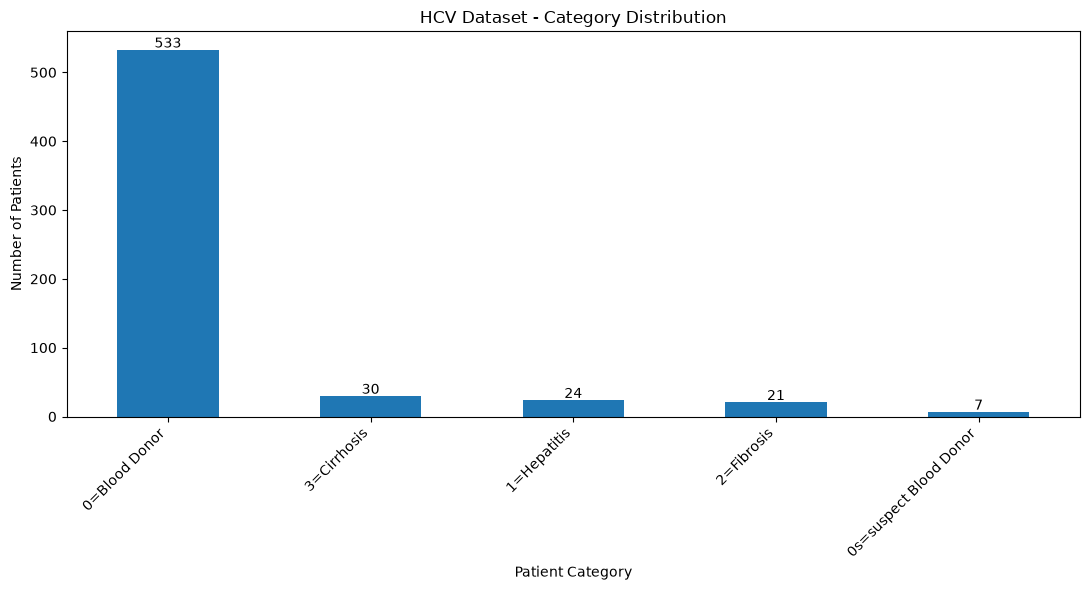

Category distribution chart saved successfully!
File exists: True


In [23]:

import matplotlib.pyplot as plt
from pathlib import Path

# Count patients in each category
category_counts = df_clean["Category"].value_counts()

# Create bar chart
plt.figure(figsize=(11, 6))

category_counts.plot(kind="bar")

plt.title("HCV Dataset - Category Distribution")
plt.xlabel("Patient Category")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45, ha="right")

# Display the number of patients above each bar
for i, count in enumerate(category_counts):
    plt.text(i, count + 3, str(count), ha="center")

plt.tight_layout()

# Save figure
figures_path = Path(
    "/home/jovyan/work/bd-a1/output/figures"
)

figures_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_path / "category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Category distribution chart saved successfully!")
print("File exists:", (
    figures_path / "category_distribution.png"
).exists())


In [24]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(
    columns=["Category", "Unnamed: 0"],
    errors="ignore"
)

y = df["Category"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# Display category distribution
print("\nTraining Category Distribution:")
print(y_train.value_counts())

print("\nTesting Category Distribution:")
print(y_test.value_counts())


Training Features: (492, 12)
Testing Features: (123, 12)

Training Labels: (492,)
Testing Labels: (123,)

Training Category Distribution:
Category
0=Blood Donor             426
3=Cirrhosis                24
1=Hepatitis                19
2=Fibrosis                 17
0s=suspect Blood Donor      6
Name: count, dtype: int64

Testing Category Distribution:
Category
0=Blood Donor             107
3=Cirrhosis                 6
1=Hepatitis                 5
2=Fibrosis                  4
0s=suspect Blood Donor      1
Name: count, dtype: int64


In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("\nPreprocessing pipeline created successfully!")


Numerical Columns:
['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']

Categorical Columns:
['Sex']

Preprocessing pipeline created successfully!


In [26]:

# Fit preprocessing using training data only
X_train_prepared = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to test data
X_test_prepared = preprocessor.transform(X_test)

print("Training Data After Preprocessing:")
print(X_train_prepared.shape)

print("\nTesting Data After Preprocessing:")
print(X_test_prepared.shape)

print("\nPreprocessing completed successfully!")


Training Data After Preprocessing:
(492, 13)

Testing Data After Preprocessing:
(123, 13)

Preprocessing completed successfully!


In [27]:

# ## Bonus: Supervised Machine Learning Model Comparison

# Two supervised machine learning algorithms were compared:
# Logistic Regression and Random Forest.

# ### Results

# Logistic Regression achieved an accuracy of 92.68%,
# while Random Forest achieved a higher accuracy of 95.12%.

# However, Logistic Regression achieved a higher macro
# F1-score (73.31%) compared with Random Forest (60.00%).

# Logistic Regression also achieved higher macro recall
# (84.40%) compared with Random Forest (58.67%).

# ### Interpretation

# Although Random Forest achieved better overall accuracy,
# Logistic Regression demonstrated better average performance
# across the five patient categories.

# Because the HCV dataset is highly imbalanced,
# macro F1-score is an important evaluation metric.

# ### Conclusion

# Logistic Regression was selected as the preferred model
# for balanced category classification based on its higher
# macro F1-score.

# However, the minority categories contain very few
# test samples, so these results should be interpreted
# with caution.


In [28]:

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_prepared, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [29]:

# Predict disease categories for test data
y_pred = model.predict(X_test_prepared)

print("Predictions Completed Successfully!")

# Display first 10 predictions
print("\nFirst 10 Predicted Categories:")
print(y_pred[:10])

# Display first 10 actual categories
print("\nFirst 10 Actual Categories:")
print(y_test.iloc[:10].values)


Predictions Completed Successfully!

First 10 Predicted Categories:
['0=Blood Donor' '0=Blood Donor' '0=Blood Donor' '0=Blood Donor'
 '0=Blood Donor' '0=Blood Donor' '0=Blood Donor' '0=Blood Donor'
 '0=Blood Donor' '0=Blood Donor']

First 10 Actual Categories:
<ArrowStringArray>
['0=Blood Donor', '0=Blood Donor', '0=Blood Donor', '0=Blood Donor',
 '0=Blood Donor', '0=Blood Donor', '0=Blood Donor', '0=Blood Donor',
 '0=Blood Donor', '0=Blood Donor']
Length: 10, dtype: str


In [30]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Display results
print("Logistic Regression Model Evaluation")
print("------------------------------------")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Logistic Regression Model Evaluation
------------------------------------
Accuracy: 0.9268
Precision: 0.6771
Recall: 0.844
F1-Score: 0.7331

Classification Report:
                        precision    recall  f1-score   support

         0=Blood Donor       0.99      0.95      0.97       107
0s=suspect Blood Donor       0.50      1.00      0.67         1
           1=Hepatitis       0.43      0.60      0.50         5
            2=Fibrosis       0.67      1.00      0.80         4
           3=Cirrhosis       0.80      0.67      0.73         6

              accuracy                           0.93       123
             macro avg       0.68      0.84      0.73       123
          weighted avg       0.94      0.93      0.93       123



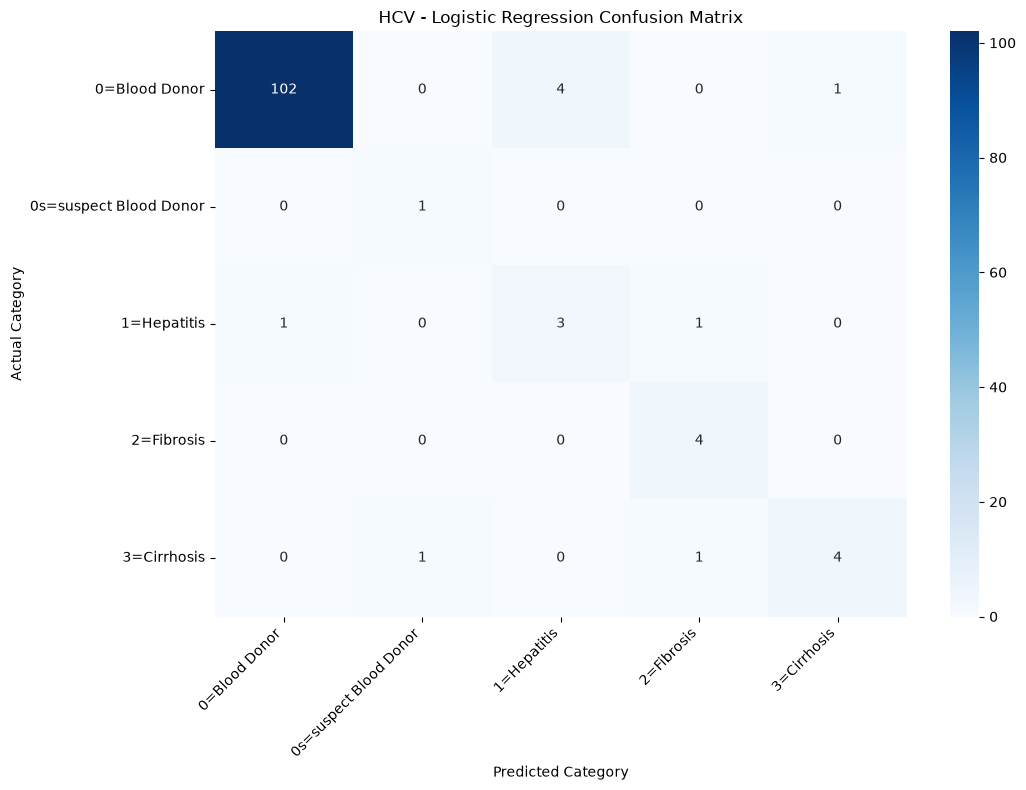

Confusion matrix saved successfully!
File exists: True


In [31]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Get category labels
labels = model.classes_

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

# Create figure
plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("HCV - Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the confusion matrix
figures_path = Path(
    "/home/jovyan/work/bd-a1/output/figures"
)

figures_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_path / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")
print("File exists:", (
    figures_path / "confusion_matrix.png"
).exists())


In [32]:

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Define output file
output_path = Path(
    "/home/jovyan/work/bd-a1/output/model_metrics.txt"
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

# Generate classification report
report = classification_report(
    y_test, y_pred, zero_division=0
)

# Generate confusion matrix
labels = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

# Save all results
with open(output_path, "w", encoding="utf-8") as file:
    file.write("HCV Classification Model Results\n")
    file.write("================================\n\n")

    file.write("Model: Logistic Regression\n")
    file.write("Training Size: 492\n")
    file.write("Testing Size: 123\n\n")

    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"Macro Precision: {precision:.4f}\n")
    file.write(f"Macro Recall: {recall:.4f}\n")
    file.write(f"Macro F1-Score: {f1:.4f}\n\n")

    file.write("Classification Report:\n")
    file.write(report)

    file.write("\nConfusion Matrix:\n")
    file.write(cm_df.to_string())

    file.write("\n\nModel Limitations:\n")
    file.write(
        "The dataset is imbalanced, and some "
        "categories have very few test samples.\n"
    )

print("Model metrics saved successfully!")
print("File exists:", output_path.exists())
print("File location:", output_path)


Model metrics saved successfully!
File exists: True
File location: /home/jovyan/work/bd-a1/output/model_metrics.txt


In [33]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train Random Forest using the same training data
rf_model.fit(X_train_prepared, y_train)

print("Random Forest Model Trained Successfully!")

# Predict test data
rf_pred = rf_model.predict(X_test_prepared)

print("Random Forest Predictions Completed!")


Random Forest Model Trained Successfully!
Random Forest Predictions Completed!


In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Compare Logistic Regression and Random Forest
comparison_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Macro Precision": [
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, rf_pred, average="macro", zero_division=0)
    ],
    "Macro Recall": [
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, rf_pred, average="macro", zero_division=0)
    ],
    "Macro F1-Score": [
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, rf_pred, average="macro", zero_division=0)
    ]
})

print("Machine Learning Model Comparison:")
display(comparison_results.round(4))


Machine Learning Model Comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.9268,0.6771,0.8440,0.7331
1,Random Forest,0.9512,0.6163,0.5867,0.6000


In [35]:

from pathlib import Path

# Path to the existing model metrics file
metrics_path = Path(
    "/home/jovyan/work/bd-a1/output/model_metrics.txt"
)

# Read existing model results
existing_content = metrics_path.read_text(encoding="utf-8")

# Prevent duplicate bonus sections
bonus_heading = "BONUS: MODEL COMPARISON"
original_content = existing_content.split(bonus_heading)[0].rstrip()

# Generate comparison table from actual model results
comparison_table = comparison_results.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
)

# Save original metrics and bonus comparison
with open(metrics_path, "w", encoding="utf-8") as file:
    file.write(original_content)

    file.write("\n\n" + bonus_heading + "\n")
    file.write("=" * 50 + "\n\n")

    file.write("Models Compared:\n")
    file.write("1. Logistic Regression\n")
    file.write("2. Random Forest\n\n")

    file.write("Model Comparison Results:\n")
    file.write(comparison_table)

    file.write("\n\nInterpretation:\n")

    file.write(
        "Random Forest achieved higher accuracy "
        "(95.12%) than Logistic Regression (92.68%).\n"
    )

    file.write(
        "Logistic Regression achieved a higher "
        "Macro F1-Score (73.31%) compared with "
        "Random Forest (60.00%).\n"
    )

    file.write(
        "Logistic Regression also achieved higher "
        "macro recall (84.40%) than "
        "Random Forest (58.67%).\n"
    )

    file.write(
        "Logistic Regression is preferred for "
        "balanced performance across categories.\n"
    )

    file.write(
        "The dataset is highly imbalanced, and "
        "minority categories contain few test samples.\n"
    )

# Verify the updated file
print("Model metrics updated successfully!")
print("File exists:", metrics_path.exists())
print("File location:", metrics_path)


Model metrics updated successfully!
File exists: True
File location: /home/jovyan/work/bd-a1/output/model_metrics.txt


In [36]:

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

# Select features without the target or row identifier
X_cluster = df.drop(
    columns=["Category", "Unnamed: 0"],
    errors="ignore"
)

# Create a separate preprocessing pipeline
cluster_preprocessor = clone(preprocessor)

# Prepare all records for clustering
X_cluster_prepared = cluster_preprocessor.fit_transform(
    X_cluster
)

print("K-Means Data Prepared Successfully!")
print("Dataset Shape:", X_cluster_prepared.shape)


K-Means Data Prepared Successfully!
Dataset Shape: (615, 13)


In [37]:

# Test different numbers of clusters
silhouette_scores = {}

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        X_cluster_prepared
    )

    score = silhouette_score(
        X_cluster_prepared,
        cluster_labels
    )

    silhouette_scores[k] = score

    print(f"k={k}, Silhouette Score={score:.4f}")

# Find k with the highest silhouette score
best_k = max(silhouette_scores, key=silhouette_scores.get)

print("\nBest k based on Silhouette Score:", best_k)
print("Best Silhouette Score:", silhouette_scores[best_k])



k=2, Silhouette Score=0.5806
k=3, Silhouette Score=0.1236
k=4, Silhouette Score=0.1271
k=5, Silhouette Score=0.1360
k=6, Silhouette Score=0.1247

Best k based on Silhouette Score: 2
Best Silhouette Score: 0.5806258252981682


In [38]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Train K-Means using the best k
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Assign each patient to a cluster
cluster_labels_final = kmeans_final.fit_predict(
    X_cluster_prepared
)

# Add cluster labels to a copy of the dataset
df_clusters = df_clean.copy()
df_clusters["Cluster"] = cluster_labels_final

print("K-Means Clustering Completed Successfully!")

print("\nNumber of Patients in Each Cluster:")
print(df_clusters["Cluster"].value_counts().sort_index())

print("\nFinal Silhouette Score:")
print(
    silhouette_score(
        X_cluster_prepared,
        cluster_labels_final
    )
)


K-Means Clustering Completed Successfully!

Number of Patients in Each Cluster:
Cluster
0     36
1    579
Name: count, dtype: int64

Final Silhouette Score:
0.5806258252981682


In [39]:

import pandas as pd

# Compare clusters with actual disease categories
cluster_comparison = pd.crosstab(
    df_clusters["Cluster"],
    df_clusters["Category"]
)

print("Cluster vs Disease Category:")
display(cluster_comparison)

# Display percentages within each cluster
print("\nCategory Percentages Within Each Cluster:")

cluster_percentages = pd.crosstab(
    df_clusters["Cluster"],
    df_clusters["Category"],
    normalize="index"
) * 100

display(cluster_percentages.round(2))


Cluster vs Disease Category:


Category,0=Blood Donor,0s=suspect Blood Donor,1=Hepatitis,2=Fibrosis,3=Cirrhosis
Cluster,,,,,
0,4,6,2,1,23
1,529,1,22,20,7



Category Percentages Within Each Cluster:


Category,0=Blood Donor,0s=suspect Blood Donor,1=Hepatitis,2=Fibrosis,3=Cirrhosis
Cluster,,,,,
0,11.11,16.67,5.56,2.78,63.89
1,91.36,0.17,3.80,3.45,1.21


In [40]:

# Compare average medical measurements by cluster
cluster_summary = df_clusters.groupby("Cluster")[
    ["Age", "ALB", "ALT", "AST", "GGT", "CREA", "PROT"]
].mean()

print("Average Medical Measurements per Cluster:")
display(cluster_summary.round(2))


Average Medical Measurements per Cluster:


,Age,ALB,ALT,AST,GGT,CREA,PROT
Cluster,,,,,,,
0,56.75,29.57,28.23,104.06,149.74,127.10,63.98
1,46.83,42.37,28.46,30.48,32.68,78.44,72.55


In [41]:
from pathlib import Path
from sklearn.metrics import silhouette_score
import pandas as pd

# Output file path
cluster_output_path = Path("/home/jovyan/work/bd-a1/output/cluster_summary.txt")

# Cluster sizes
cluster_sizes = df_clusters["Cluster"].value_counts().sort_index()

# Silhouette score
final_silhouette = silhouette_score(X_cluster_prepared, cluster_labels_final)

# Cluster vs category table
cluster_vs_category = pd.crosstab(
    df_clusters["Cluster"],
    df_clusters["Category"]
)

# Cluster percentages
cluster_percentages = pd.crosstab(
    df_clusters["Cluster"],
    df_clusters["Category"],
    normalize="index"
) * 100

# Average measurements
cluster_means = df_clusters.groupby("Cluster")[
    ["Age", "ALB", "ALT", "AST", "GGT", "CREA", "PROT"]
].mean().round(2)

# Save summary
with open(cluster_output_path, "w", encoding="utf-8") as file:
    file.write("HCV K-Means Clustering Summary\n")
    file.write("====================================\n\n")

    file.write(f"Chosen number of clusters (k): {best_k}\n")
    file.write(f"Silhouette Score: {final_silhouette:.4f}\n\n")

    file.write("Cluster Sizes:\n")
    file.write(cluster_sizes.to_string())
    file.write("\n\n")

    file.write("Cluster vs Disease Category:\n")
    file.write(cluster_vs_category.to_string())
    file.write("\n\n")

    file.write("Category Percentages Within Each Cluster:\n")
    file.write(cluster_percentages.round(2).to_string())
    file.write("\n\n")

    file.write("Average Medical Measurements per Cluster:\n")
    file.write(cluster_means.to_string())
    file.write("\n\n")

    file.write("Interpretation:\n")
    file.write(
        "Cluster 0 contains older patients with lower ALB and PROT, "
        "and much higher AST, GGT, and CREA. It is dominated by cirrhosis cases, "
        "suggesting a more clinically severe group.\n"
    )
    file.write(
        "Cluster 1 contains most of the blood donor records and shows more normal "
        "average laboratory values, suggesting a healthier group overall.\n"
    )
    file.write(
        "The clusters do not exactly match the known disease labels, which is expected "
        "because K-Means is an unsupervised learning method.\n"
    )

print("Cluster summary saved successfully!")
print("File exists:", cluster_output_path.exists())
print("File location:", cluster_output_path)

Cluster summary saved successfully!
File exists: True
File location: /home/jovyan/work/bd-a1/output/cluster_summary.txt


Average Laboratory Measurements:


,ALT,AST,GGT
Category,,,
0=Blood Donor,26.63,26.55,29.04
3=Cirrhosis,22.97,107.46,129.44


<Figure size 1100x600 with 0 Axes>

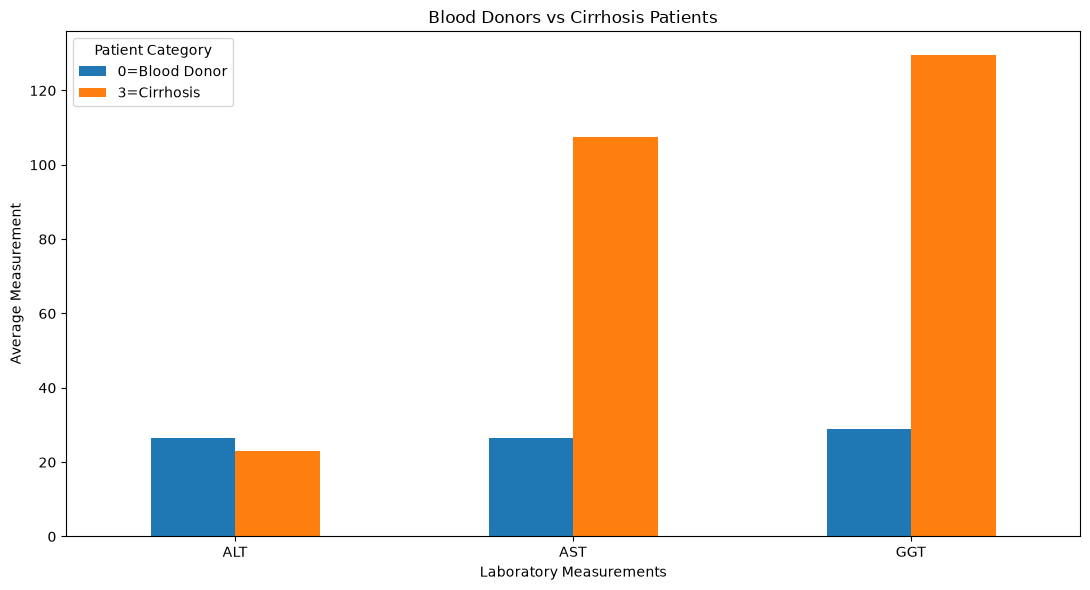

Group comparison chart saved successfully!
File exists: True


In [42]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Select two patient categories
selected_groups = [
    "0=Blood Donor",
    "3=Cirrhosis"
]

# Select laboratory measurements
selected_features = ["ALT", "AST", "GGT"]

# Filter the dataset
comparison_data = df_clean[
    df_clean["Category"].isin(selected_groups)
]

# Calculate average measurements
group_means = comparison_data.groupby("Category")[
    selected_features
].mean().reindex(selected_groups)

print("Average Laboratory Measurements:")
display(group_means.round(2))

# Create the comparison chart
plt.figure(figsize=(11, 6))

group_means.T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Blood Donors vs Cirrhosis Patients")
plt.xlabel("Laboratory Measurements")
plt.ylabel("Average Measurement")
plt.xticks(rotation=0)
plt.legend(title="Patient Category")
plt.tight_layout()

# Save the chart
figures_path = Path(
    "/home/jovyan/work/bd-a1/output/figures"
)

figures_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_path / "group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Group comparison chart saved successfully!")
print(
    "File exists:",
    (figures_path / "group_comparison.png").exists()
)
